# Filtrage d'image

Un filtre remplace chaque pixel par une combinaison de ses voisins. Là où les [statistiques d'image](Statistiques_d'image.ipynb) résument des valeurs, le filtrage tient compte de leur arrangement spatial : un contour, un grain, une tache isolée.

Ce notebook couvre les familles usuelles. Les filtres linéaires passe-bas (moyenne, gaussien) et le médian, face à trois bruits : gaussien, impulsionnel, speckle multiplicatif. Les filtres passe-haut (Sobel, laplacien, renforcement, Canny). Une lecture fréquentielle, qui explique les noms « passe-bas » et « passe-haut ». Puis la morphologie mathématique : érosion, dilatation, ouverture, fermeture, chapeau haut de forme, squelette. Il se termine par ce qu'il est raisonnable d'en faire avant de segmenter des types de forêt sur une orthophoto.

La photo est la même que dans le notebook de statistiques, téléchargée depuis Wikimedia Commons.

**Parcours** — les numéros sont ceux des sections.

| Section | Question |
|---|---|
| 1 | Qu'est-ce qu'une convolution ? |
| 2 | Pourquoi un filtre moyen est-il un passe-bas, et que change la taille ? |
| 3 | À quoi sert l'écart-type d'un gaussien ? |
| 4 | Comment reconnaître un bruit gaussien d'un bruit impulsionnel ? |
| 5 | Quel passe-bas atténue quel bruit ? |
| 6 | Pourquoi le speckle radar ne se traite pas comme une impulsion ? |
| 7 | Que séparent les deux filtres de Sobel, le module et la direction ? |
| 8 | Que voit un laplacien qu'un gradient ne voit pas ? |
| 9 | Comment renforcer un contour sans changer son emplacement ? |
| 10 | Où sont les basses et les hautes fréquences ? |
| 11 | Comment Canny assemble-t-il ces filtres ? |
| 12 | Que font l'érosion, la dilatation, l'ouverture, la fermeture et le squelette ? |
| 13 | Que filtrer, et que ne pas filtrer, avant une carte de types de forêt ? |


## 1. Un filtre est une convolution

On appelle **noyau** le petit tableau des coefficients. Pour un noyau $h$ centré, le pixel de sortie vaut

$$
(g * h)(i, j) = \sum_{k} \sum_{l} h(k, l) \, g(i + k, j + l)
$$

C'est une somme pondérée du voisinage. Le filtre est **linéaire** : filtrer la somme de deux images donne la somme des images filtrées.

Deux cas se lisent sur la somme des coefficients. Si elle vaut 1, une zone plate garde son niveau : le filtre peut être un passe-bas. Si elle vaut 0, une zone plate devient noire et seuls les changements survivent : le filtre est un passe-haut. Les sections 7 et 8 utiliseront des noyaux de somme nulle. Ici, le noyau moyen $3 \times 3$ vaut $1/9$ partout, et la somme vaut 1.

Au bord, le voisinage dépasse de l'image. On complète par **réflexion** : la dernière ligne est recopiée en miroir, plutôt que par des zéros qui dessineraient un cadre noir.


### Installer les dépendances et charger la photo


In [1]:
%pip install -q pillow matplotlib numpy scipy


Note: you may need to restart the kernel to use updated packages.


332 lignes × 500 colonnes, valeurs de 0 à 255
Somme du noyau moyen 3×3 : 1.0
    0.111   0.111   0.111
    0.111   0.111   0.111
    0.111   0.111   0.111


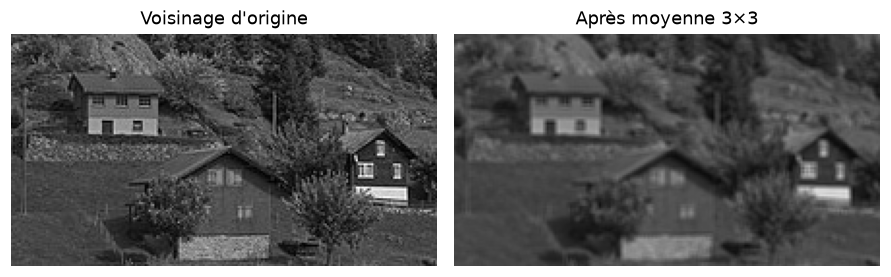

In [2]:
import time
import urllib.request
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from scipy.fft import fft2, fftshift
from scipy.ndimage import (
    binary_closing,
    binary_dilation,
    binary_erosion,
    binary_opening,
    convolve,
    gaussian_filter,
    grey_opening,
    label,
    median_filter,
    uniform_filter,
)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

URL_PAYSAGE = (
    "https://upload.wikimedia.org/wikipedia/commons/thumb/"
    "1/14/Landscape_Arnisee-region.JPG/500px-Landscape_Arnisee-region.JPG"
)


def telecharger_image(url, essais=3):
    """Télécharge une photo et la renvoie en niveaux de gris, float de 0 à 255."""
    derniere_erreur = None
    for essai in range(essais):
        try:
            requete = urllib.request.Request(
                url, headers={"User-Agent": "filtrage-image/1.0 (educational)"}
            )
            with urllib.request.urlopen(requete, timeout=60) as reponse:
                image = Image.open(BytesIO(reponse.read())).convert("L")
            return np.asarray(image).astype(np.float64)
        except Exception as erreur:
            derniere_erreur = erreur
            time.sleep(1.5 * (essai + 1))
    raise RuntimeError(f"Téléchargement impossible pour {url}") from derniere_erreur


def noyau_moyen(taille):
    """Noyau carré dont les coefficients valent 1 / taille²."""
    return np.full((taille, taille), 1.0 / (taille * taille))


def ecrire_noyau(noyau):
    """Affiche un noyau avec trois décimales."""
    for ligne in noyau:
        print("  " + " ".join(f"{valeur:7.3f}" for valeur in ligne))


image = telecharger_image(URL_PAYSAGE)
print(
    f"{image.shape[0]} lignes × {image.shape[1]} colonnes, "
    f"valeurs de {image.min():.0f} à {image.max():.0f}"
)

noyau3 = noyau_moyen(3)
print(f"Somme du noyau moyen 3×3 : {noyau3.sum():.1f}")
ecrire_noyau(noyau3)

moyenne3 = convolve(image, noyau3, mode="reflect")
cadrage = (slice(150, 270), slice(30, 250))

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.6))
axes[0].imshow(image[cadrage], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Voisinage d'origine")
axes[1].imshow(moyenne3[cadrage], cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Après moyenne 3×3")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire la convolution

Le cadrage montre les chalets. Après la moyenne $3 \times 3$, les arêtes des toits sont un peu moins nettes et le grain de l'herbe aussi : chaque pixel a été remplacé par la moyenne de neuf valeurs. Le niveau général ne change pas, parce que les coefficients somment à 1. L'effet est encore léger. La section suivante augmente la fenêtre.


## 2. Le filtre moyen et la taille du voisinage

La même moyenne, avec un côté de 3, 7 puis 15 pixels. Pour mesurer ce que le filtre enlève, on calcule le **module du gradient** de Sobel, détaillé à la section 7 : il est grand sur un contour et presque nul sur une zone plate. Sa moyenne sur l'image est une énergie de contours.


Filtre            Module moyen
Aucun                       80


Moyenne 3                   45
Moyenne 7                   25
Moyenne 15                  14


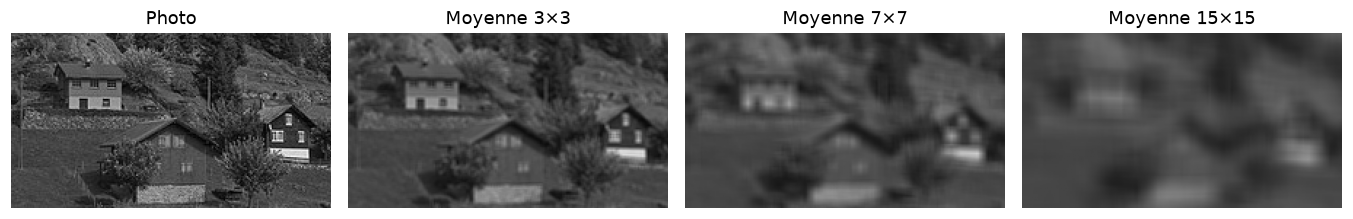

In [3]:
def module_gradient(image):
    """Module de Sobel. Les noyaux sont ceux de la section 7."""
    horizontal = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], dtype=float)
    vertical = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
    derivee_lignes = convolve(image, horizontal, mode="reflect")
    derivee_colonnes = convolve(image, vertical, mode="reflect")
    return np.hypot(derivee_lignes, derivee_colonnes)


print(f"{'Filtre':16}{'Module moyen':>14}")
print(f"{'Aucun':16}{module_gradient(image).mean():14.0f}")

fig, axes = plt.subplots(1, 4, figsize=(12.4, 3.3))
axes[0].imshow(image[cadrage], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Photo")
for ax, taille in zip(axes[1:], (3, 7, 15)):
    filtree = uniform_filter(image, size=taille, mode="reflect")
    ax.imshow(filtree[cadrage], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Moyenne {taille}×{taille}")
    print(f"{'Moyenne ' + str(taille):16}{module_gradient(filtree).mean():14.0f}")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire la taille

Le module moyen du gradient passe de **80** à **45**, **25**, puis **14**. Les contours s'effacent à mesure que la fenêtre grandit : à $15 \times 15$, les fenêtres des chalets se dissolvent et les arbres deviennent une masse.

On parle de **passe-bas** parce que le filtre laisse passer les variations lentes (le ciel, une prairie, le flanc d'une montagne) et atténue les variations rapides (un toit, une branche, un caillou). La taille choisit la rapidité que l'on accepte encore. Une fenêtre de 15 pixels moyenne ensemble des objets qui ne se ressemblent pas : le mur clair et l'ombre du toit finissent dans le même pixel.


## 3. Le filtre gaussien et le rôle de σ

Le noyau moyen traite le centre de la fenêtre et son bord de la même façon. Le noyau gaussien donne plus de poids au centre. En deux dimensions, avec un écart-type $\sigma$,

$$
h(k, l) = \frac{1}{Z} \exp\left( -\frac{k^2 + l^2}{2\sigma^2} \right)
$$

$Z$ est choisi pour que la somme des coefficients vaille 1. On le construit ici sur un support $7 \times 7$, comme dans l'exercice d'origine, pour deux valeurs de $\sigma$.


σ = 0.6   centre = 0.441   bord = 0.000
σ = 2.0   centre = 0.047   bord = 0.015


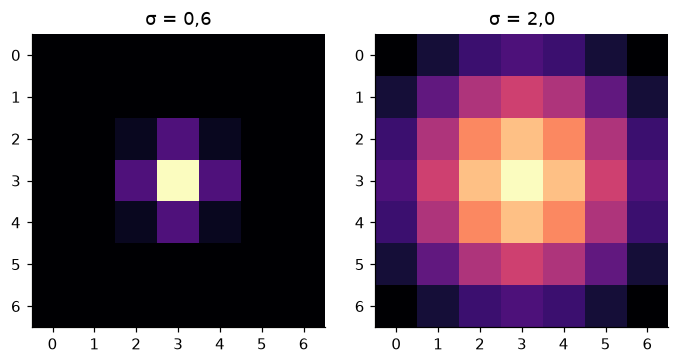

Gaussien 7×7, σ = 0,6        module 58
Gaussien 7×7, σ = 2,0        module 28
Moyenne 7×7                  module 25


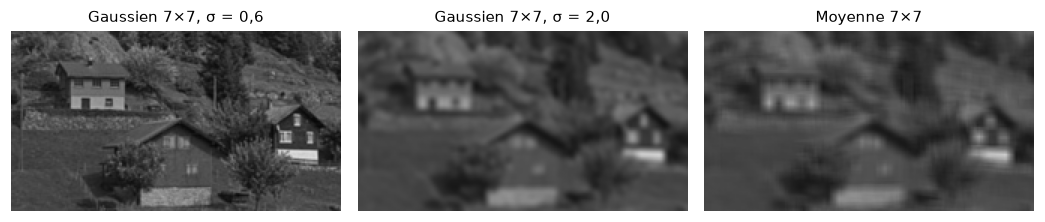

In [4]:
def noyau_gaussien(taille, sigma):
    """Gaussienne 2D normalisée, tronquée à un carré de côté `taille`."""
    demi = (taille - 1) / 2
    lignes, colonnes = np.ogrid[-demi : demi + 1, -demi : demi + 1]
    noyau = np.exp(-(lignes**2 + colonnes**2) / (2 * sigma**2))
    noyau[noyau < np.finfo(noyau.dtype).eps * noyau.max()] = 0
    return noyau / noyau.sum()


fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.2))
for ax, sigma in zip(axes, (0.6, 2.0)):
    noyau = noyau_gaussien(7, sigma)
    ax.imshow(noyau, cmap="magma")
    ax.set_title(f"σ = {sigma}".replace(".", ","))
    ax.set_xticks(range(7))
    ax.set_yticks(range(7))
    print(f"σ = {sigma}   centre = {noyau[3, 3]:.3f}   bord = {noyau[3, 0]:.3f}")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.3))
titres = []
images_filtrees = []
for sigma in (0.6, 2.0):
    images_filtrees.append(convolve(image, noyau_gaussien(7, sigma), mode="reflect"))
    titres.append(f"Gaussien 7×7, σ = {sigma}".replace(".", ","))
images_filtrees.append(uniform_filter(image, size=7, mode="reflect"))
titres.append("Moyenne 7×7")
for ax, filtree, titre in zip(axes, images_filtrees, titres):
    ax.imshow(filtree[cadrage], cmap="gray", vmin=0, vmax=255)
    ax.set_title(titre, fontsize=10)
    ax.axis("off")
    print(f"{titre:28} module {module_gradient(filtree).mean():.0f}")
fig.tight_layout()
plt.show()


### Lire σ

Pour $\sigma = 0{,}6$, le coefficient central vaut **0,44** et les bords du $7 \times 7$ sont nuls : la fenêtre affichée est trop grande pour ce $\sigma$, et le filtre ne touche presque pas l'image. Le module du gradient reste à **58**, contre 80 sans filtre.

Pour $\sigma = 2$, le coefficient central tombe à **0,05** et le bord vaut encore **0,015**. Le noyau est presque plat, donc proche d'une moyenne, et le module tombe à **28**. La moyenne $7 \times 7$ de la section 2 était à 25. Les deux images se ressemblent.

$\sigma$ règle l'étendue utile du flou, pas le côté du tableau. Une règle pratique : le support doit couvrir environ $\pm 3\sigma$, sinon on tronque la gaussienne (elle se rapproche d'un filtre moyen) ou on affiche des zéros inutiles. Dans la suite, `gaussian_filter(image, sigma=...)` choisit lui-même un support assez grand. Le gaussien reste un passe-bas linéaire de somme 1, comme la moyenne, avec un flou sans le poids excessif des coins de la fenêtre.


## 4. Bruit gaussien et bruit impulsionnel

On ajoute à la photo deux bruits connus, pour avoir une image propre de référence.

Le **bruit gaussien additif** ajoute à chaque pixel un tirage $\mathcal{N}(0, 25^2)$, en niveaux de gris, puis on borne le résultat à $[0, 255]$. Tous les pixels sont touchés, un peu.

Le **bruit impulsionnel** (poivre et sel) remplace **5 %** des pixels par 0 ou 255, une fois sur deux. Les autres pixels restent exacts.


Pixels remplacés par une impulsion : 5.0 %


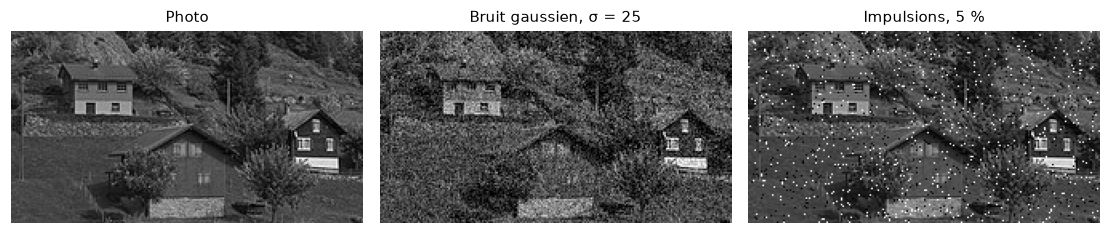

In [5]:
rng_gaussien = np.random.default_rng(0)
bruit_gaussien = np.clip(image + rng_gaussien.normal(0, 25, image.shape), 0, 255)

rng_impulsion = np.random.default_rng(1)
pixels_touches = rng_impulsion.random(image.shape) < 0.05
tirage_zero = rng_impulsion.random(image.shape) < 0.5
bruit_impulsion = image.copy()
bruit_impulsion[pixels_touches & tirage_zero] = 0
bruit_impulsion[pixels_touches & ~tirage_zero] = 255

print(f"Pixels remplacés par une impulsion : {100 * pixels_touches.mean():.1f} %")

fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.4))
for ax, photo, titre in zip(
    axes,
    (image, bruit_gaussien, bruit_impulsion),
    ("Photo", "Bruit gaussien, σ = 25", "Impulsions, 5 %"),
):
    ax.imshow(photo[cadrage], cmap="gray", vmin=0, vmax=255)
    ax.set_title(titre, fontsize=10)
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire les deux bruits

Le bruit gaussien donne un grain continu : l'herbe, le mur et le toit sont tous un peu moins lisibles, sans pixel aberrant. Les impulsions sont des points noirs et blancs isolés, et entre ces points l'image est intacte. Ce n'est pas le même défaut, et ce ne sera pas le même filtre.


## 5. Moyen, gaussien ou médian

On compare trois passe-bas.

La moyenne $3 \times 3$ et la moyenne $7 \times 7$ sont linéaires. Le gaussien d'écart-type 1 aussi. Le **médian** ne l'est pas : il remplace le pixel par la valeur centrale du voisinage trié. Une impulsion isolée, très grande ou très petite, sort du tri sans entraîner la moyenne avec elle.

L'erreur est l'écart quadratique moyen avec la photo propre :

$$
\mathrm{RMSE} = \sqrt{ \frac{1}{N} \sum (\hat{x} - x)^2 }
$$

Sur les impulsions, on compte aussi la part des pixels touchés que le filtre ramène à moins de 10 niveaux de la valeur d'origine.


Bruit gaussien
Filtre              RMSE
Sans filtre         24.6
Moyen 3             16.2
Moyen 7             18.5
Gaussien σ=1        15.1
Médian 3            17.3
Médian 7            18.3

Bruit impulsionnel
Filtre              RMSE   Corrigées
Sans filtre         31.6         0 %


Moyen 3             17.8         30 %
Moyen 7             19.0         51 %
Gaussien σ=1        16.4         24 %
Médian 3            13.8         63 %
Médian 7            17.5         61 %


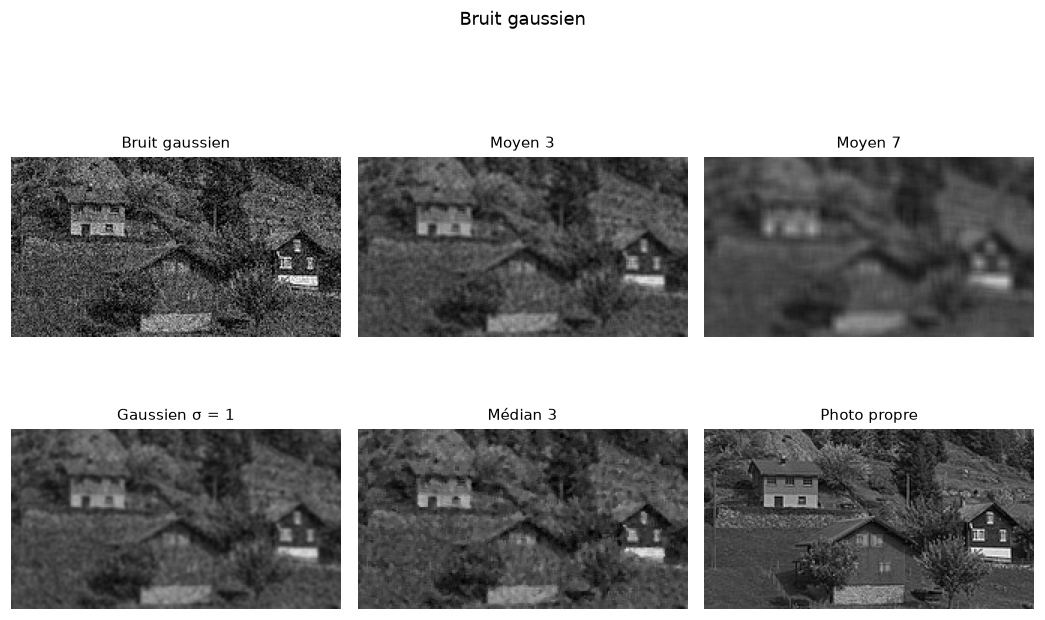

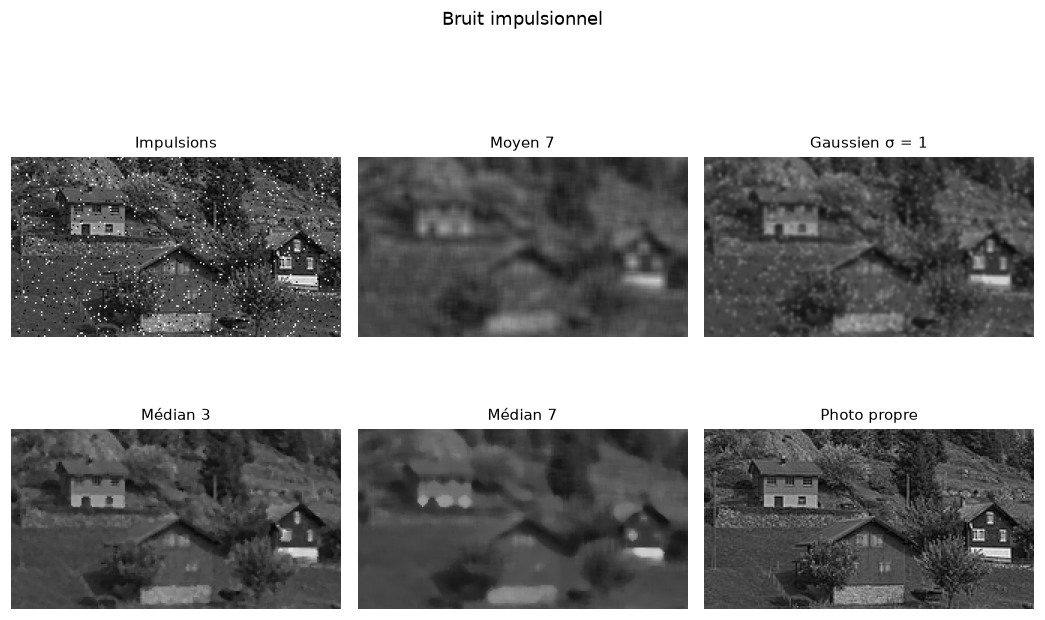

In [6]:
def ecart_quadratique(estimee, reference):
    return float(np.sqrt(np.mean((estimee - reference) ** 2)))


def passe_bas(photo):
    return {
        "Moyen 3": uniform_filter(photo, size=3, mode="reflect"),
        "Moyen 7": uniform_filter(photo, size=7, mode="reflect"),
        "Gaussien σ=1": gaussian_filter(photo, sigma=1.0, mode="reflect"),
        "Médian 3": median_filter(photo, size=3, mode="reflect"),
        "Médian 7": median_filter(photo, size=7, mode="reflect"),
    }


print("Bruit gaussien")
print(f"{'Filtre':16}{'RMSE':>8}")
print(f"{'Sans filtre':16}{ecart_quadratique(bruit_gaussien, image):8.1f}")
for nom, filtree in passe_bas(bruit_gaussien).items():
    print(f"{nom:16}{ecart_quadratique(filtree, image):8.1f}")

print("\nBruit impulsionnel")
print(f"{'Filtre':16}{'RMSE':>8}{'Corrigées':>12}")
print(f"{'Sans filtre':16}{ecart_quadratique(bruit_impulsion, image):8.1f}{'0 %':>12}")
for nom, filtree in passe_bas(bruit_impulsion).items():
    ramenees = (np.abs(filtree - image) < 10) & pixels_touches
    part = 100 * ramenees.sum() / pixels_touches.sum()
    print(f"{nom:16}{ecart_quadratique(filtree, image):8.1f}{part:11.0f} %")

fig, axes = plt.subplots(2, 3, figsize=(9.6, 6.2))
panneaux = [
    (bruit_gaussien, "Bruit gaussien"),
    (uniform_filter(bruit_gaussien, 3), "Moyen 3"),
    (uniform_filter(bruit_gaussien, 7), "Moyen 7"),
    (gaussian_filter(bruit_gaussien, 1), "Gaussien σ = 1"),
    (median_filter(bruit_gaussien, 3), "Médian 3"),
    (image, "Photo propre"),
]
for ax, (photo, titre) in zip(axes.ravel(), panneaux):
    ax.imshow(photo[cadrage], cmap="gray", vmin=0, vmax=255)
    ax.set_title(titre, fontsize=10)
    ax.axis("off")
fig.suptitle("Bruit gaussien", y=1.02)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(9.6, 6.2))
panneaux = [
    (bruit_impulsion, "Impulsions"),
    (uniform_filter(bruit_impulsion, 7), "Moyen 7"),
    (gaussian_filter(bruit_impulsion, 1), "Gaussien σ = 1"),
    (median_filter(bruit_impulsion, 3), "Médian 3"),
    (median_filter(bruit_impulsion, 7), "Médian 7"),
    (image, "Photo propre"),
]
for ax, (photo, titre) in zip(axes.ravel(), panneaux):
    ax.imshow(photo[cadrage], cmap="gray", vmin=0, vmax=255)
    ax.set_title(titre, fontsize=10)
    ax.axis("off")
fig.suptitle("Bruit impulsionnel", y=1.02)
fig.tight_layout()
plt.show()


### Lire le choix du filtre

| Filtre | RMSE, bruit gaussien | RMSE, impulsions | Impulsions ramenées à ±10 |
|---|---:|---:|---:|
| Sans filtre | 24,6 | 31,6 | 0 % |
| Moyen 3×3 | 16,2 | 17,8 | 30 % |
| Moyen 7×7 | 18,5 | 19,0 | 51 % |
| Gaussien, σ = 1 | **15,1** | 16,4 | 24 % |
| Médian 3×3 | 17,3 | **13,8** | **63 %** |
| Médian 7×7 | 18,3 | 17,5 | 61 % |

Sur le bruit gaussien, le gaussien gagne. La moyenne $7 \times 7$ fait **moins bien** que la moyenne $3 \times 3$ (18,5 contre 16,2) : la grande fenêtre efface des contours réels, et cette erreur dépasse le bruit qu'elle enlève. Le grain des figures le montre, les chalets de la moyenne $7 \times 7$ sont flous.

Sur les impulsions, le médian $3 \times 3$ gagne, en RMSE et en pixels corrigés. La moyenne et le gaussien étalent chaque point noir ou blanc en une tache grise : on le voit sur les murs. Le médian $7 \times 7$ corrige à peu près autant d'impulsions que le $3 \times 3$ (61 % contre 63 %), mais il floute davantage, donc le RMSE remonte.

Le médian $3 \times 3$ ne corrige pas 100 % des impulsions : à 5 %, certaines se touchent, et une paire de points aberrants dans une fenêtre $3 \times 3$ peut survivre au tri.


## 6. Bruit multiplicatif : speckle et filtre de Lee

Le bruit des sections 4 et 5 était ajouté, ou remplaçait quelques pixels. Sur une image **radar**, le grain de chatoiement (**speckle**) est multiplicatif : la valeur mesurée est la réflectivité multipliée par un facteur aléatoire. Pour une intensité moyennée sur $L$ vues, ce facteur suit une loi Gamma de moyenne 1 et de variance $1/L$. Plus la surface est claire, plus le grain est fort en valeur absolue.

L'image radar du TP d'origine n'est pas dans ce dossier. On simule donc un speckle à **4 vues** sur la même photo. Le mécanisme — tous les pixels touchés, variance proportionnelle au carré de l'intensité — est celui qui justifie un filtre dédié.

Le **filtre de Lee** (1980) mélange le pixel et la moyenne locale. $m$ et $v$ sont la moyenne et la variance dans la fenêtre, $z$ le pixel bruité :

$$
\hat{x} = m + k (z - m), \qquad k = \mathrm{clip}\left( \frac{v - m^2 / L}{v \, (1 + 1/L)} \,,\, 0,\, 1 \right)
$$

Là où la variance locale vaut juste la variance du speckle ($m^2 / L$), $k = 0$ et le filtre renvoie la moyenne. Là où la variance dépasse le speckle, $k$ augmente et le filtre reste plus près du pixel observé : un contour est moins étalé.


Image                    CV ciel    RMSE
Photo                      0.066     0.0
Speckle 4 vues             0.349    48.5
Moyenne 7×7                0.057    22.2
Médian 7×7                 0.100    23.7
Lee 7×7                    0.057    20.5

Poids de Lee, moyenne dans le ciel : 0.00
Poids de Lee, moyenne dans la forêt : 0.26


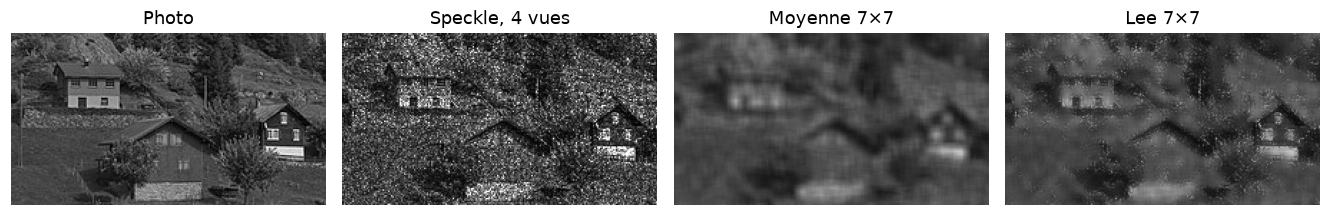

In [7]:
def filtre_lee(photo, taille, vues):
    """Filtre de Lee pour un speckle d'intensité à `vues` looks."""
    moyenne = uniform_filter(photo, size=taille, mode="reflect")
    moment2 = uniform_filter(photo**2, size=taille, mode="reflect")
    variance = np.clip(moment2 - moyenne**2, 0, None)
    variance_speckle = 1.0 / vues
    poids = (variance - moyenne**2 * variance_speckle) / (
        variance * (1 + variance_speckle) + 1e-6
    )
    poids = np.clip(poids, 0, 1)
    return moyenne + poids * (photo - moyenne), poids


rng_speckle = np.random.default_rng(2)
vues = 4
speckle = rng_speckle.gamma(vues, 1.0 / vues, image.shape)
bruit_speckle = np.clip(image * speckle, 0, 255)
lee, poids_lee = filtre_lee(bruit_speckle, taille=7, vues=vues)
lee = np.clip(lee, 0, 255)
moyenne7 = uniform_filter(bruit_speckle, size=7, mode="reflect")
median7 = median_filter(bruit_speckle, size=7, mode="reflect")

ciel = (slice(5, 35), slice(150, 350))
foret = (slice(85, 130), slice(5, 85))


def coefficient_variation(zone):
    return float(zone.std() / zone.mean())


print(f"{'Image':22}{'CV ciel':>10}{'RMSE':>8}")
for nom, photo in (
    ("Photo", image),
    ("Speckle 4 vues", bruit_speckle),
    ("Moyenne 7×7", moyenne7),
    ("Médian 7×7", median7),
    ("Lee 7×7", lee),
):
    print(
        f"{nom:22}{coefficient_variation(photo[ciel]):10.3f}"
        f"{ecart_quadratique(photo, image):8.1f}"
    )
print(f"\nPoids de Lee, moyenne dans le ciel : {poids_lee[ciel].mean():.2f}")
print(f"Poids de Lee, moyenne dans la forêt : {poids_lee[foret].mean():.2f}")

fig, axes = plt.subplots(1, 4, figsize=(12.2, 3.3))
for ax, photo, titre in zip(
    axes,
    (image, bruit_speckle, moyenne7, lee),
    ("Photo", "Speckle, 4 vues", "Moyenne 7×7", "Lee 7×7"),
):
    ax.imshow(photo[cadrage], cmap="gray", vmin=0, vmax=255)
    ax.set_title(titre)
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire le speckle

| Image | CV du ciel | RMSE |
|---|---:|---:|
| Photo | 0,066 | 0 |
| Speckle, 4 vues | 0,349 | 48,5 |
| Moyenne 7×7 | 0,057 | 22,2 |
| Médian 7×7 | 0,100 | 23,7 |
| Lee 7×7 | 0,057 | **20,5** |

Le coefficient de variation (écart-type divisé par la moyenne) du ciel mesure le grain dans une zone qui devrait être lisse. Il passe de 0,066 à 0,349 avec le speckle. La moyenne le ramène à 0,057. Le médian s'arrête à 0,100 : contrairement aux impulsions, presque tous les pixels sont bruités, et le tri ne trouve pas de pixel sain à recopier.

Le poids de Lee vaut **0** dans le ciel : le filtre y est exactement la moyenne, d'où le même CV. Dans la forêt il vaut **0,26** : un quart du pixel observé, trois quarts de la moyenne locale. Les lisières des chalets restent un peu plus nettes que sous la moyenne seule, et le RMSE descend de 22,2 à 20,5. Le gain est réel et modeste. Le grain résiduel sur les arbres vient de là : la variance locale mélange le speckle et la texture vraie du feuillage, et le filtre ne sait pas les distinguer. Un filtre de Lee ne remplace pas un filtre pensé pour la texture, il évite surtout d'étaler les contours comme le ferait une grande moyenne.


## 7. Filtre de Sobel : orientation des contours

Le passe-haut le plus simple est une dérivée. Le filtre de **Sobel** l'estime dans deux directions. La somme de chaque noyau vaut 0 : une zone plate donne 0.

$$
h_{\text{horizontal}} =
\begin{bmatrix}
1 & 2 & 1 \\
0 & 0 & 0 \\
-1 & -2 & -1
\end{bmatrix}
\qquad
h_{\text{vertical}} =
\begin{bmatrix}
-1 & 0 & 1 \\
-2 & 0 & 2 \\
-1 & 0 & 1
\end{bmatrix}
$$

Le noyau horizontal réagit quand le niveau change **entre les lignes** : il renforce les contours horizontaux (un toit, l'horizon). Le noyau vertical renforce les contours verticaux (un mur, un tronc). Le filtre de Prewitt est la même idée avec des 1 à la place des 2.

Le **module** rassemble les deux directions, $\sqrt{g_h^2 + g_v^2}$. La **direction** est l'angle $\arctan2(g_h, g_v)$, entre $-\pi$ et $\pi$. Elle n'a de sens que là où le module est grand : dans l'herbe, le gradient est un bruit et l'angle aussi. On n'affiche donc l'angle que sur les pixels au-dessus du 92e centile du module.


Somme des coefficients, horizontal : 0
Somme des coefficients, vertical   : 0
Seuil (92e centile) : 198   part des pixels : 8 %


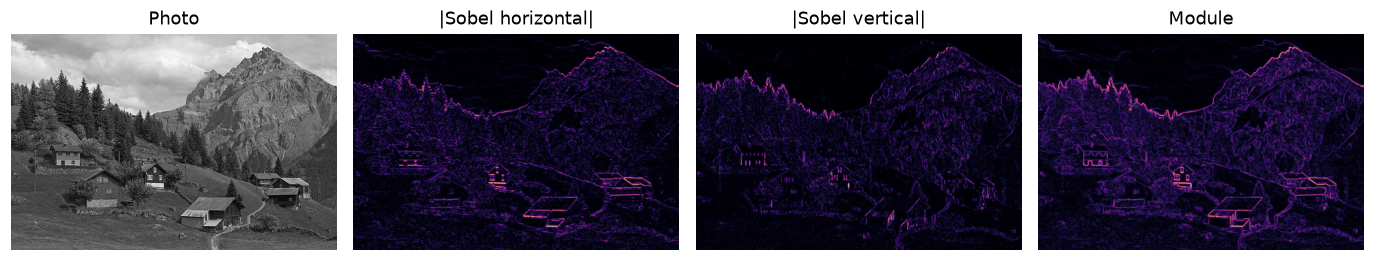

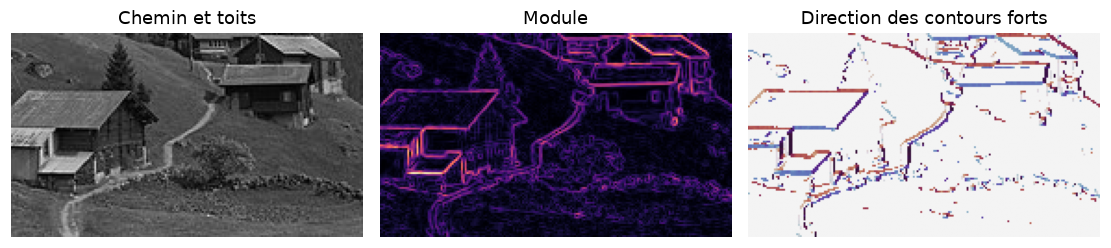

In [8]:
noyau_horizontal = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], dtype=float)
noyau_vertical = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
print(f"Somme des coefficients, horizontal : {noyau_horizontal.sum():.0f}")
print(f"Somme des coefficients, vertical   : {noyau_vertical.sum():.0f}")

gradient_h = convolve(image, noyau_horizontal, mode="reflect")
gradient_v = convolve(image, noyau_vertical, mode="reflect")
module = np.hypot(gradient_h, gradient_v)
direction = np.arctan2(gradient_h, gradient_v)

seuil_direction = np.percentile(module, 92)
print(
    f"Seuil (92e centile) : {seuil_direction:.0f}   "
    f"part des pixels : {100 * (module >= seuil_direction).mean():.0f} %"
)

fig, axes = plt.subplots(1, 4, figsize=(12.6, 3.4))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Photo")
axes[1].imshow(np.abs(gradient_h), cmap="magma")
axes[1].set_title("|Sobel horizontal|")
axes[2].imshow(np.abs(gradient_v), cmap="magma")
axes[2].set_title("|Sobel vertical|")
axes[3].imshow(module, cmap="magma")
axes[3].set_title("Module")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

zoom = (slice(220, 330), slice(280, 470))
palette = plt.cm.twilight.copy()
palette.set_bad("#f4f4f4")
direction_masquee = np.where(module >= seuil_direction, direction, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.6))
axes[0].imshow(image[zoom], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Chemin et toits")
axes[1].imshow(module[zoom], cmap="magma")
axes[1].set_title("Module")
axes[2].imshow(direction_masquee[zoom], cmap=palette, vmin=-np.pi, vmax=np.pi)
axes[2].set_title("Direction des contours forts")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire Sobel

Le filtre horizontal allume les toits, le pied de la montagne, les limites horizontales des prés. Le filtre vertical allume les murs, les troncs et les cassures verticales de la crête. Le module additionne les deux : un contour oblique, comme le chemin, apparaît même s'il n'est ni horizontal ni vertical.

Environ **8 %** des pixels dépassent le module 198. Sur le zoom, ces pixels dessinent les toits, les murs et le chemin. Les pixels d'un même toit partagent une couleur de direction, les murs une autre : la couleur est l'orientation du contour, pas son intensité. Le chemin, qui tourne, change de couleur le long de son tracé. En dehors de ces lignes, le fond est laissé gris : afficher l'angle partout colorerait l'herbe au hasard.

Un seuil sur le module détecte des contours, pas des objets. La forêt s'allume autant qu'un bâtiment, parce que le feuillage est une suite de petits contours. C'est la texture déjà mesurée par l'écart-type local dans le notebook de statistiques.


## 8. Laplacien et laplacien de gaussienne

Le laplacien est une dérivée seconde, la somme des dérivées secondes horizontale et verticale :

$$
h =
\begin{bmatrix}
0 & 1 & 0 \\
1 & -4 & 1 \\
0 & 1 & 0
\end{bmatrix}
$$

La somme des coefficients vaut encore 0. Sur un contour, la dérivée première est un pic et la dérivée seconde passe par zéro : le laplacien change de signe de part et d'autre du contour. En valeur absolue, un contour propre apparaît donc comme une **double ligne**.

Une dérivée seconde amplifie le bruit plus qu'une dérivée première. On lisse donc d'abord par un gaussien, puis on applique le laplacien. C'est le **laplacien de gaussienne** (LoG).


Somme des coefficients : 0
Moyenne de |laplacien|, photo propre : 36
Moyenne de |laplacien|, photo bruitée : 98


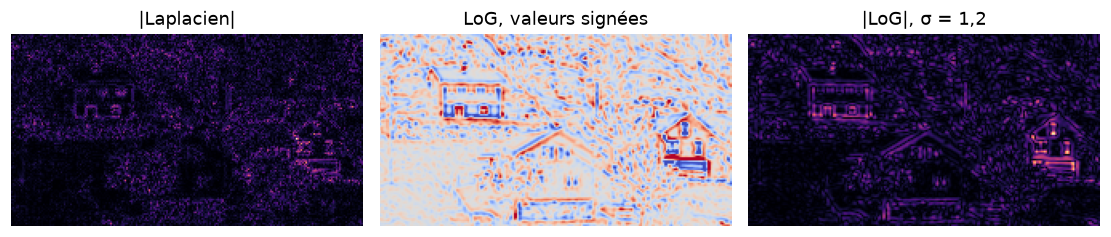

In [9]:
noyau_laplacien = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=float)
print(f"Somme des coefficients : {noyau_laplacien.sum():.0f}")

laplacien = convolve(image, noyau_laplacien, mode="reflect")
laplacien_bruit = convolve(bruit_gaussien, noyau_laplacien, mode="reflect")
laplacien_gaussien = convolve(
    gaussian_filter(image, sigma=1.2), noyau_laplacien, mode="reflect"
)
print(f"Moyenne de |laplacien|, photo propre : {np.abs(laplacien).mean():.0f}")
print(f"Moyenne de |laplacien|, photo bruitée : {np.abs(laplacien_bruit).mean():.0f}")

limite = np.percentile(np.abs(laplacien_gaussien), 99)
fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.5))
axes[0].imshow(np.abs(laplacien)[cadrage], cmap="magma")
axes[0].set_title("|Laplacien|")
axes[1].imshow(
    laplacien_gaussien[cadrage], cmap="coolwarm", vmin=-limite, vmax=limite
)
axes[1].set_title("LoG, valeurs signées")
axes[2].imshow(np.abs(laplacien_gaussien)[cadrage], cmap="magma")
axes[2].set_title("|LoG|, σ = 1,2")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire le laplacien

Sur la photo propre, la moyenne de la valeur absolue du laplacien vaut **36**. Sur la photo avec le bruit gaussien de la section 4, elle passe à **98**. Le grain est dérivé deux fois, et il domine les vrais contours : le premier panneau, déjà sur la photo propre, est moucheté par l'herbe.

Après un gaussien d'écart-type 1,2, le LoG signé montre le changement de signe : de part et d'autre d'un toit, une frange positive et une frange négative. La valeur absolue donne le double contour annoncé. Le module de Sobel, lui, fait une seule crête, localisée sur le contour. Les deux ne servent pas au même usage : le module dit où le niveau change vite, le laplacien dit de quel côté la pente s'infléchit, au prix d'une sensibilité plus forte au bruit.


## 9. Renforcement par masque flou

Un passe-haut peut se rajouter à l'image au lieu de la remplacer. Le **masque flou** est la photo moins une version gaussienne : positif sur un détail plus clair que son voisinage, négatif sur un détail plus sombre. On en réinjecte une fraction :

$$
r = g + \alpha \, (g - g * h_{\sigma})
$$

Avec $\alpha = 1{,}5$ et $\sigma = 1{,}5$. Les contours restent à leur place : on augmente leur amplitude, on ne les déplace pas.


Module moyen du gradient, photo      : 80
Module moyen du gradient, renforcée  : 164


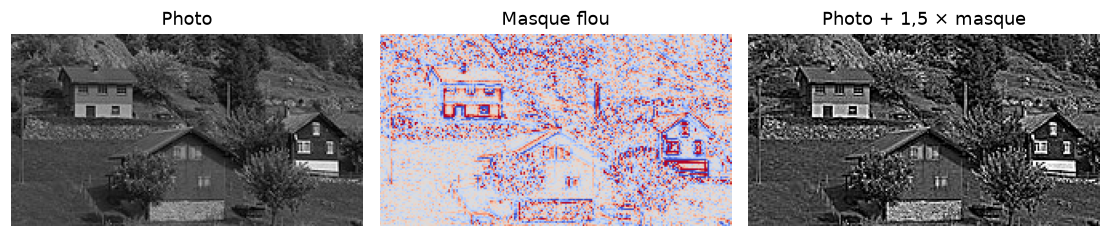

In [10]:
flou = gaussian_filter(image, sigma=1.5)
masque_flou = image - flou
renforcee = np.clip(image + 1.5 * masque_flou, 0, 255)
print(f"Module moyen du gradient, photo      : {module_gradient(image).mean():.0f}")
print(f"Module moyen du gradient, renforcée  : {module_gradient(renforcee).mean():.0f}")

fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.5))
axes[0].imshow(image[cadrage], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Photo")
axes[1].imshow(masque_flou[cadrage], cmap="coolwarm", vmin=-40, vmax=40)
axes[1].set_title("Masque flou")
axes[2].imshow(renforcee[cadrage], cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Photo + 1,5 × masque")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire le renforcement

Le module moyen du gradient passe de **80** à **164** : les contours sont environ deux fois plus marqués. Sur le cadrage, les cadres des fenêtres et le bord des toits se lisent mieux. Le masque flou est l'image des détails, le même objet que le passe-haut.

Ce renforcement amplifie aussi le grain. Sur une photo déjà bruitée, il rend le bruit plus visible. Et il change les valeurs : un pixel renforcé n'est plus comparable à celui d'une autre date ou d'une autre tuile. C'est un outil de lecture visuelle, pas un prétraitement radiométrique.


## 10. Lecture fréquentielle

La transformée de Fourier 2D range l'image par rapidité de variation. Après un `fftshift`, le **centre** porte les basses fréquences (les grandes plages lentement variables) et les **bords** les hautes fréquences (les détails fins). On affiche $\log(1 + |F|)$, et on retire la moyenne de l'image avant le calcul pour que le pixel central ne soit pas seulement le niveau de gris moyen.

Un filtre linéaire devient un produit dans ce domaine. Un passe-bas atténue les bords du spectre. Un passe-haut atténue le centre.


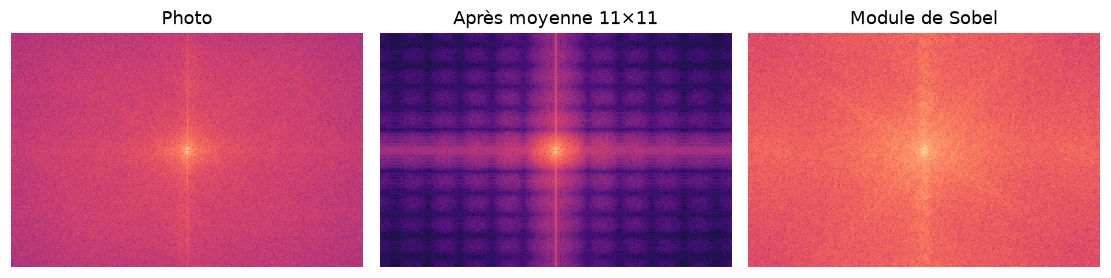

In [11]:
def spectre(photo):
    """Log-module du spectre, basses fréquences au centre."""
    centree = photo - photo.mean()
    return np.log1p(np.abs(fftshift(fft2(centree))))


fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.6))
for ax, photo, titre in zip(
    axes,
    (image, uniform_filter(image, size=11, mode="reflect"), module),
    ("Photo", "Après moyenne 11×11", "Module de Sobel"),
):
    ax.imshow(spectre(photo), cmap="magma")
    ax.set_title(titre)
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire les trois spectres

La photo concentre beaucoup d'énergie au centre, avec une croix : les structures horizontales et verticales du paysage (horizon, crête, murs) s'alignent sur les axes du spectre.

Après la moyenne $11 \times 11$, les coins s'éteignent. Les détails fins ont été supprimés dans l'image, ils disparaissent aux bords du spectre. Les bandes sombres régulières ne sont pas dans le paysage : la transformée d'un noyau carré est un sinus cardinal, qui s'annule à intervalles réguliers. Un gaussien n'a pas ces annulations, son spectre est une autre gaussienne. C'est une raison de le préférer à la moyenne quand on veut un flou sans ces lobes.

Le module de Sobel garde la croix des contours orientés. Une zone constante a été mise à zéro par les noyaux de somme nulle, donc les grandes plages plates pèsent moins qu'avant au centre. Passe-bas et passe-haut se lisent ici directement.


## 11. Canny : assembler les filtres

Le détecteur de **Canny** enchaîne des opérations déjà vues.

1. Un gaussien ($\sigma = 1$) limite le bruit avant la dérivée.
2. Sobel fournit le module et la direction.
3. La **suppression des non-maxima** amincit : un pixel n'est gardé que s'il est un maximum local du module dans la direction du gradient. Le contour devient une ligne.
4. Un **double seuil** avec hystérésis ferme la détection. Au-dessus du seuil haut, le pixel est un contour sûr. Entre le seuil bas et le seuil haut, il n'est gardé que s'il touche un contour sûr, de proche en proche. En dessous du seuil bas, il est rejeté.

Les seuils sont pris sur le module après amincissement : le seuil haut est le 85e centile des pixels encore non nuls, le seuil bas vaut 35 % du seuil haut.


Seuil bas 36, seuil haut 102
Pixels conservés : 12.0 %


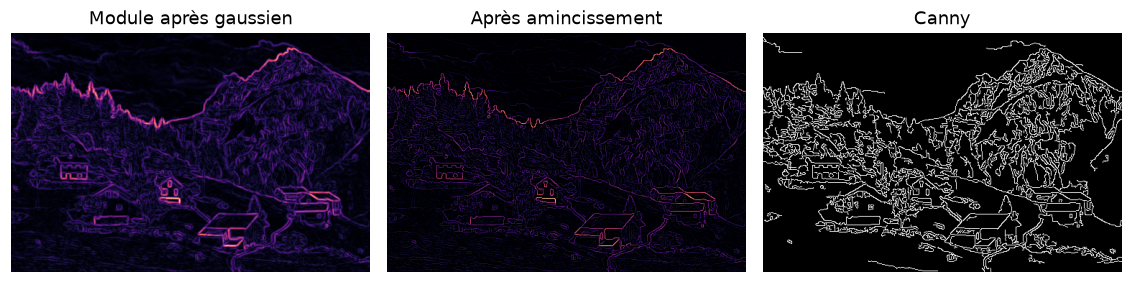

In [12]:
def suppression_non_maxima(module_gradient, direction):
    """Met à zéro les pixels qui ne sont pas un maximum local le long du gradient."""
    angle = np.rad2deg(direction) % 180
    voisinage = np.pad(module_gradient, 1, mode="edge")
    centre = voisinage[1:-1, 1:-1]
    orientations = [
        ((angle < 22.5) | (angle >= 157.5), voisinage[1:-1, :-2], voisinage[1:-1, 2:]),
        ((angle >= 22.5) & (angle < 67.5), voisinage[:-2, 2:], voisinage[2:, :-2]),
        ((angle >= 67.5) & (angle < 112.5), voisinage[:-2, 1:-1], voisinage[2:, 1:-1]),
        ((angle >= 112.5) & (angle < 157.5), voisinage[:-2, :-2], voisinage[2:, 2:]),
    ]
    garder = np.zeros(module_gradient.shape, dtype=bool)
    for masque, premier, second in orientations:
        garder |= masque & (centre >= premier) & (centre >= second)
    return np.where(garder, module_gradient, 0.0)


def canny(photo, sigma=1.0, centile=85, rapport_bas=0.35):
    """Contours de Canny. Renvoie le masque booléen et les deux seuils."""
    lissee = gaussian_filter(photo, sigma=sigma)
    derivee_h = convolve(
        lissee, np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], float), mode="reflect"
    )
    derivee_v = convolve(
        lissee, np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float), mode="reflect"
    )
    module_lisse = np.hypot(derivee_h, derivee_v)
    aminci = suppression_non_maxima(module_lisse, np.arctan2(derivee_h, derivee_v))
    seuil_haut = np.percentile(aminci[aminci > 0], centile)
    seuil_bas = rapport_bas * seuil_haut
    forts = aminci >= seuil_haut
    faibles = (aminci >= seuil_bas) & ~forts
    etiquettes, nombre = label(forts | faibles, structure=np.ones((3, 3), dtype=bool))
    garder = np.zeros(nombre + 1, dtype=bool)
    garder[np.unique(etiquettes[forts])] = True
    garder[0] = False
    return garder[etiquettes], seuil_bas, seuil_haut, module_lisse, aminci


contours, seuil_bas, seuil_haut, module_lisse, module_aminci = canny(image)
print(f"Seuil bas {seuil_bas:.0f}, seuil haut {seuil_haut:.0f}")
print(f"Pixels conservés : {100 * contours.mean():.1f} %")

fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.6))
axes[0].imshow(module_lisse, cmap="magma")
axes[0].set_title("Module après gaussien")
axes[1].imshow(module_aminci, cmap="magma")
axes[1].set_title("Après amincissement")
axes[2].imshow(contours, cmap="gray")
axes[2].set_title("Canny")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire Canny

L'amincissement transforme les crêtes épaisses du module en lignes. L'hystérésis enlève ensuite les crêtes trop faibles pour être un contour, tout en gardant un morceau faible s'il prolonge un contour déjà sûr : les arêtes des toits restent continues.

Les chalets, le chemin et la crête sortent bien. La forêt aussi. Canny ne décide pas qu'un contour de branche est moins « objet » qu'un contour de toit : il décide seulement qu'un changement de niveau est localement maximal et assez fort. Sur une canopée, ce critère est vrai presque partout. Une carte de types de forêt ne se lit pas sur cette image binaire.


## 12. Morphologie mathématique

Les filtres précédents combinent des niveaux de gris. La morphologie combine des **formes**, à l'aide d'un **élément structurant** : ici un disque, l'ensemble des pixels à une distance donnée du centre.

Sur une image binaire, avec le disque posé en chaque pixel :

- l'**érosion** garde le pixel seulement si le disque tient entièrement dans l'objet. L'objet rétrécit, les taches plus petites que le disque disparaissent, les trous s'agrandissent ;
- la **dilatation** marque le pixel dès que le disque touche l'objet. L'objet grossit, les trous plus petits que le disque se bouchent, les taches s'arrondissent ;
- l'**ouverture** est une érosion suivie d'une dilatation. Les petites taches restent supprimées, et les objets assez grands retrouvent à peu près leur taille ;
- la **fermeture** est une dilatation suivie d'une érosion. Les petits trous se bouchent, le contour extérieur bouge peu.

On le voit d'abord sur une forme connue : un disque et un carré, avec un trou chacun et des taches ajoutées autour. L'ouverture utilise un disque de rayon 2, la fermeture un disque de rayon 4, assez grand pour les trous une fois l'ouverture passée.

Le **squelette** morphologique répète l'idée d'ouverture : à chaque pas on enlève la bordure (ce que l'érosion retire et que l'ouverture ne rend pas) et on érode à nouveau. Il reste l'axe médian, une ligne à égale distance des bords.


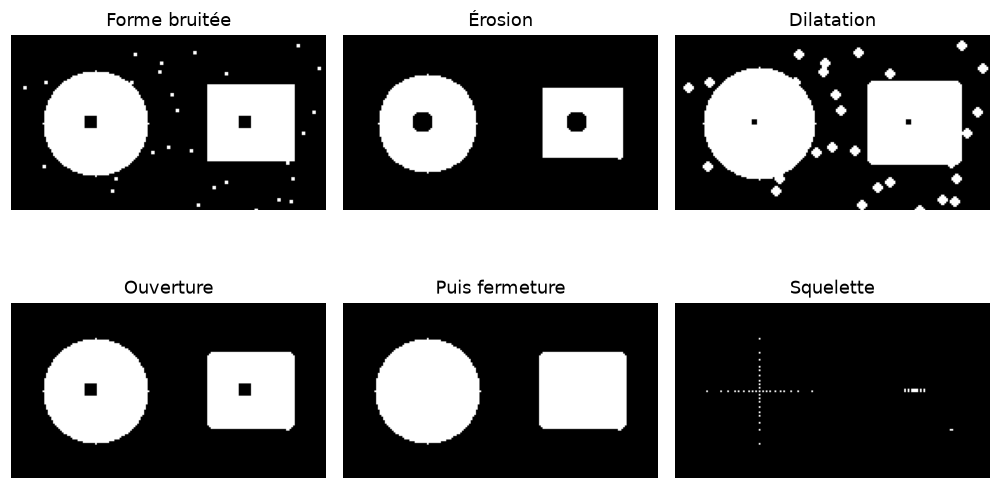

In [13]:
def disque(rayon):
    """Élément structurant circulaire de rayon donné, en pixels."""
    lignes, colonnes = np.ogrid[-rayon : rayon + 1, -rayon : rayon + 1]
    return (lignes**2 + colonnes**2) <= rayon**2


def squelette(masque):
    """Squelette morphologique par ouvertures successives."""
    element = np.ones((3, 3), dtype=bool)
    resultat = np.zeros(masque.shape, dtype=bool)
    courant = masque.astype(bool)
    while courant.any():
        ouvert = binary_opening(courant, structure=element)
        resultat |= courant & ~ouvert
        suivant = binary_erosion(courant, structure=element)
        if suivant.sum() == courant.sum():
            break
        courant = suivant
    return resultat


forme = np.zeros((100, 180), dtype=bool)
yy, xx = np.ogrid[:100, :180]
forme[(yy - 50) ** 2 + (xx - 48) ** 2 <= 30**2] = True
forme[28:72, 112:162] = True
forme[46:53, 42:49] = False
forme[46:53, 130:137] = False

rng_forme = np.random.default_rng(2)
bruitee = forme.copy()
for ligne, colonne in zip(rng_forme.integers(0, 100, 35), rng_forme.integers(0, 180, 35)):
    if not forme[ligne, colonne]:
        bruitee[ligne : ligne + 2, colonne : colonne + 2] = True

erosion = binary_erosion(bruitee, structure=disque(2))
dilatation = binary_dilation(bruitee, structure=disque(2))
ouverture = binary_opening(bruitee, structure=disque(2))
fermeture = binary_closing(ouverture, structure=disque(4))
squelette_forme = squelette(fermeture)

fig, axes = plt.subplots(2, 3, figsize=(9.2, 5.6))
for ax, photo, titre in zip(
    axes.ravel(),
    (bruitee, erosion, dilatation, ouverture, fermeture, squelette_forme),
    ("Forme bruitée", "Érosion", "Dilatation", "Ouverture", "Puis fermeture", "Squelette"),
):
    ax.imshow(photo, cmap="gray", vmin=0, vmax=1)
    ax.set_title(titre)
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire les six formes

L'érosion efface les taches et amincit le disque et le carré ; leurs trous grandissent. La dilatation fait l'inverse : les taches deviennent des pastilles et les trous se réduisent. L'ouverture combine les deux dans l'ordre utile : les taches, plus petites que le disque, ne reviennent pas, et les deux grandes formes retrouvent leur contour. Les trous, eux, sont toujours là.

La fermeture qui suit les bouche, parce que le disque de rayon 4 ne tient pas dans un trou de cette taille. Le squelette de la forme nettoyée n'est plus le contour : c'est une croix au centre du disque, et un court segment au centre du carré, légèrement plus large que haut. L'axe médian ne décrit pas le type d'objet, seulement sa géométrie une fois la forme pleine.


### Le même enchaînement sur la photo

On seuille les pixels $\le 70$. Dans le notebook de statistiques, la forêt de cette photo a une moyenne de 64 et la prairie de 79 : le seuil garde une grande part du sombre, forêt et ombres de la roche comprises. Ce n'est pas une carte de forêt. C'est un masque binaire avec le même défaut que l'exercice d'origine sur l'eau : des faux positifs petits (des ombres isolées) et des trous (des pixels plus clairs à l'intérieur d'un massif).

L'ouverture puis la fermeture utilisent un disque de rayon 2.


Masque           : 29 % des pixels, 2022 composantes
Après ouverture  : 15 % des pixels, 132 composantes
Après fermeture  : 16 % des pixels


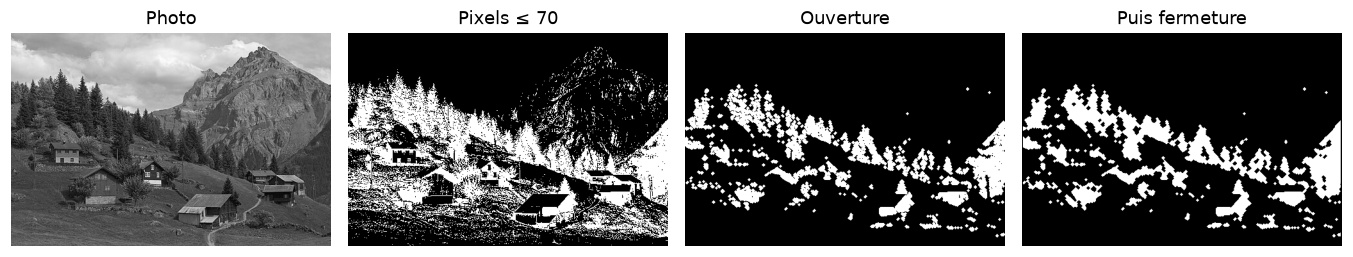

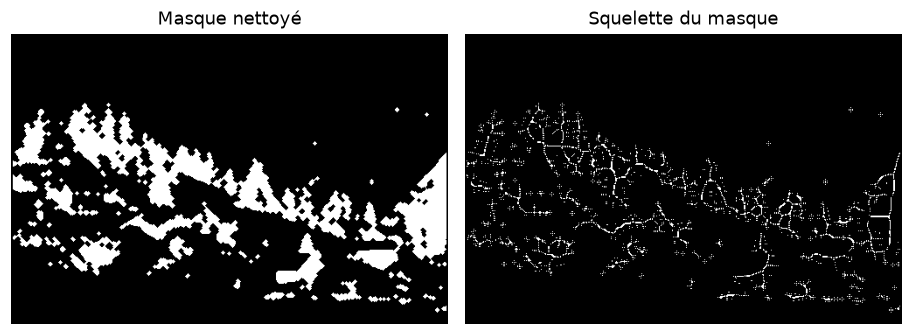

In [14]:
masque_sombre = image <= 70
ouvert = binary_opening(masque_sombre, structure=disque(2))
ferme = binary_closing(ouvert, structure=disque(2))
_, composantes_avant = label(masque_sombre, structure=np.ones((3, 3), dtype=bool))
_, composantes_apres = label(ouvert, structure=np.ones((3, 3), dtype=bool))

print(f"Masque           : {100 * masque_sombre.mean():.0f} % des pixels, {composantes_avant} composantes")
print(f"Après ouverture  : {100 * ouvert.mean():.0f} % des pixels, {composantes_apres} composantes")
print(f"Après fermeture  : {100 * ferme.mean():.0f} % des pixels")

fig, axes = plt.subplots(1, 4, figsize=(12.4, 3.4))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Photo")
axes[1].imshow(masque_sombre, cmap="gray")
axes[1].set_title("Pixels ≤ 70")
axes[2].imshow(ouvert, cmap="gray")
axes[2].set_title("Ouverture")
axes[3].imshow(ferme, cmap="gray")
axes[3].set_title("Puis fermeture")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

squelette_masque = squelette(ferme)
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.5))
axes[0].imshow(ferme, cmap="gray")
axes[0].set_title("Masque nettoyé")
axes[1].imshow(squelette_masque, cmap="gray")
axes[1].set_title("Squelette du masque")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire le masque réel

Le seuil couvre **29 %** des pixels et les découpe en **2 022** composantes connexes : la forêt, mais aussi beaucoup de petites ombres sur la roche et entre les arbres. L'ouverture descend à **15 %** et à **132** composantes. Le disque de rayon 2 ne tient pas dans une ombre de quelques pixels, qui disparaît. Il ne tient pas non plus dans un jeune arbre isolé ou une branche : l'ouverture ne distingue pas un faux positif d'un objet fin réel.

La fermeture remonte à **16 %**. Elle bouche des trous plus petits que le disque, à l'intérieur des massifs, et elle peut aussi coller deux massifs séparés par un passage étroit.

Le squelette du masque nettoyé suit l'axe de chaque tache restante. Sur une forêt, cela donne un réseau de branches, pas une essence. Le squelette est adapté à une forme allongée dont l'axe a un sens — un cours d'eau, une route, une haie — une fois cette forme déjà isolée.


### Chapeau haut de forme

Les opérations précédentes étaient binaires. En niveaux de gris, l'ouverture est un minimum local suivi d'un maximum local : elle gomme les pics plus petits que l'élément structurant. Le **chapeau haut de forme** est l'image moins cette ouverture. Il garde les objets clairs plus petits que le disque, et il annule les grandes plages claires. Le disque a ici un rayon de 8 pixels.


Chapeau : moyenne 28, 99e centile 124


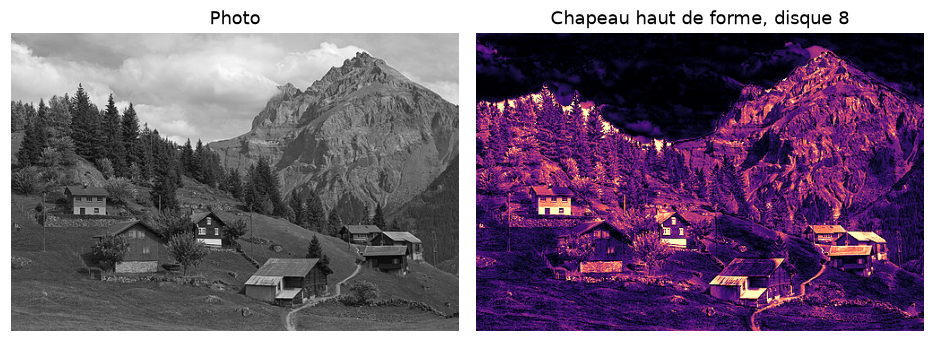

In [15]:
chapeau = image - grey_opening(image, footprint=disque(8))
print(
    f"Chapeau : moyenne {chapeau.mean():.0f}, "
    f"99e centile {np.percentile(chapeau, 99):.0f}"
)

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.6))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Photo")
axes[1].imshow(chapeau, cmap="magma", vmin=0, vmax=np.percentile(chapeau, 99))
axes[1].set_title("Chapeau haut de forme, disque 8")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire le chapeau

Le ciel, grande zone claire, s'éteint. Les toits, le chemin et les petites taches claires de la roche restent. Le chapeau ne mesure pas « clair ou sombre » : il mesure « plus clair que le voisinage, à l'échelle du disque ». Avec un rayon de 8, un toit entre dans le disque, le ciel non. Le relief de la paroi rocheuse, fait de détails plus petits que 8 pixels, reste visible lui aussi. Comme pour la fenêtre de texture, la taille de l'élément structurant choisit l'échelle des objets extraits.


## 13. Bilan — filtrer avant de segmenter une forêt

Les filtres de ce notebook ne classent pas. Ils préparent une image, ou ils nettoient un masque déjà obtenu. Pour une orthophoto dont on veut des types de forêt (feuillu, résineux, mélange, trouée, non-forêt), l'ordre compte autant que le choix du filtre.

### Ce que chaque famille fait, et où elle cesse d'aider

| Outil | Usage | À éviter |
|---|---|---|
| Moyenne, gaussien (§2, §3) | Réduire un bruit additif présent sur tous les pixels. Le gaussien, avec un $\sigma$ petit devant la taille des houppiers, abîme moins les contours qu'une grande moyenne. | Une fenêtre plus grande que les objets que l'on veut garder. Sur le bruit gaussien de la section 5, la moyenne $7 \times 7$ avait un RMSE pire que la $3 \times 3$. |
| Médian (§5) | Pixels morts, impulsions, quelques valeurs aberrantes. Le $3 \times 3$ a le mieux corrigé les 5 % d'impulsions. | Le speckle, qui touche tous les pixels : le médian $7 \times 7$ nettoyait moins le ciel que la moyenne. |
| Lee (§6) | Speckle radar, quand le nombre de vues est connu. Dans une zone lisse il revient à la moyenne (poids 0 dans le ciel) et il préserve mieux un contour (RMSE 20,5 contre 22,2). | S'en servir pour effacer la texture de la canopée. Dans la forêt le poids restait à 0,26 : le filtre voit une variance, pas une essence. |
| Sobel, Canny (§7, §11) | Routes, lisières, ombres portées, limites de peuplement déjà franches. La direction n'est lisible que sur les contours forts. | Produire la carte de types à partir du seul module. La canopée est pleine de contours ; Canny les garde. |
| Laplacien (§8) | Repérer un changement de concavité, après un lissage. | L'appliquer à une image bruitée sans gaussien : la moyenne de la valeur absolue passait de 36 à 98. |
| Masque flou (§9) | Rendre une orthophoto plus lisible pour la photo-interprétation. | L'utiliser comme variable d'un classifieur, ou le calculer tuile par tuile : les valeurs ne sont plus comparables, pour la même raison que l'égalisation d'histogramme. |
| Ouverture, fermeture (§12) | Nettoyer un masque déjà seuillé ou déjà classé. L'ouverture a fait passer le masque sombre de 2 022 composantes à 132. | Choisir le disque sans le convertir en mètres. Un rayon de 2 pixels sur une orthophoto à 50 cm fait 2,5 m de diamètre : une trouée réelle plus étroite disparaît avec les faux positifs. |
| Chapeau haut de forme (§12) | Extraire des objets clairs plus petits que le disque : bâti, chemin, avant de les confondre avec une classe claire. | Séparer deux essences. Le chapeau ne voit pas la couleur, seulement l'échelle. |
| Squelette (§12) | Axe d'une forme déjà propre et allongée : ruisseau, haie, piste. | L'axe d'un massif forestier. On obtient le réseau vu sur le masque, pas un type. |

### Un enchaînement

1. **Regarder le bruit avant de filtrer.** Impulsions rares : médian $3 \times 3$. Bruit additif faible et partout : gaussien de petit $\sigma$. Radar : Lee, ou une moyenne si l'on veut surtout une radiométrie lisse à l'intérieur d'une parcelle, en sachant que les lisières bougent.
2. **Ne pas lisser avant une texture.** L'écart-type local du notebook de statistiques mesure le feuillage. Un gaussien préalable mesure le filtre. Si un débruitage est indispensable, sa fenêtre doit rester plus petite que la couronne, à la résolution au sol de l'orthophoto.
3. **Réserver les contours aux limites, pas aux classes.** Sobel ou Canny peuvent devenir une variable parmi d'autres (une lisière n'a pas la même texture que l'intérieur du peuplement) ou servir à contrôler un masque. Ils ne remplacent pas les bandes, un indice de végétation et la texture.
4. **Filtrer le masque, pas la radiométrie, pour la morphologie.** Ouverture puis fermeture une fois la classe prédite. Le rayon se choisit en mètres : assez grand pour les erreurs isolées, plus petit que les trouées et les routes que l'on veut conserver.
5. **Enchaîner avec une méthode du niveau 3 ou du niveau 4** sur les variables radiométriques et de texture, avec le même contrôle qu'ailleurs : un jeu de test qui ne jouxte pas l'entraînement, et une lecture par classe. Un bon RMSE de débruitage ne dit rien sur l'essence minoritaire.

### Ce que ce notebook ne remplace pas

Le speckle simulé est une loi Gamma indépendante d'un pixel à l'autre. Un vrai speckle radar est spatialement corrélé, et des filtres plus spécialisés (Lee raffiné, Frost, filtres non locaux) existent pour ça. Les seuils — 70 en niveau de gris, 92e centile, 85e centile de Canny, rayons 2, 4 et 8 — sont choisis pour cette photo. Une autre résolution ou une autre essence demande de les recalculer, de préférence en mètres sur le terrain et non en pixels sur l'écran.


### Sources

- Photo : [Landscape Arnisee-region.JPG](https://commons.wikimedia.org/wiki/File:Landscape_Arnisee-region.JPG), Wikimedia Commons.
- Filtre de Lee : J.-S. Lee, « Digital image enhancement and noise filtering by use of local statistics », IEEE Trans. Pattern Analysis and Machine Intelligence, 1980.
- Détecteur de contours : J. Canny, « A computational approach to edge detection », IEEE Trans. Pattern Analysis and Machine Intelligence, 1986.
- Les mêmes opérations dans SciPy : `scipy.ndimage` (`uniform_filter`, `gaussian_filter`, `median_filter`, `convolve`, `binary_opening`, `grey_opening`) et `scipy.fft`.

### Limites

Les trois bruits sont ajoutés à une photo déjà nette, avec des graines aléatoires fixées. Un capteur réel mélange souvent plusieurs défauts, et le bruit n'est pas toujours indépendant du niveau de gris — le speckle l'est, le bruit gaussien simulé ici ne l'est pas. Le squelette dépend de la connexité $3 \times 3$ choisie dans la fonction. Le spectre est affiché en logarithme : une zone sombre y est faible, pas nulle.
